In [1]:
# import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import RidgeClassifier, LogisticRegression
from sklearn.metrics import accuracy_score, ConfusionMatrixDisplay

In [2]:
fileName = r"C:\Users\user\Downloads\LA_AQS_2023.csv"
df= pd.read_csv(fileName)
print(df.shape)
df.head()

(22160, 34)


,State Code,County Code,Site Number,Parameter Code,POC,Latitude,Longitude,Datum,Parameter Name,Duration Description,...,AQI,Daily Criteria Indicator,Tribe Name,State Name,County Name,City Name,Local Site Name,Address,MSA or CBSA Name,Data Source
0,6,37,1103,68103,1,34.06659,-118.22688,WGS84,Ambient Min Temperature,24 HOUR,...,.,Y,NaN,California,Los Angeles,Los Angeles,Los Angeles-North Main Street,"1630 N MAIN ST, LOS ANGELES","Los Angeles-Long Beach-Anaheim, CA",AQS Data Mart
1,6,37,1103,42602,3,34.06659,-118.22688,WGS84,Nitrogen dioxide (NO2),1 HOUR,...,16,Y,NaN,California,Los Angeles,Los Angeles,Los Angeles-North Main Street,"1630 N MAIN ST, LOS ANGELES","Los Angeles-Long Beach-Anaheim, CA",AQS Data Mart
2,6,37,1103,62201,1,34.06659,-118.22688,WGS84,Relative Humidity,1 HOUR,...,.,Y,NaN,California,Los Angeles,Los Angeles,Los Angeles-North Main Street,"1630 N MAIN ST, LOS ANGELES","Los Angeles-Long Beach-Anaheim, CA",AQS Data Mart
3,6,37,1103,62101,1,34.06659,-118.22688,WGS84,Outdoor Temperature,1 HOUR,...,.,Y,NaN,California,Los Angeles,Los Angeles,Los Angeles-North Main Street,"1630 N MAIN ST, LOS ANGELES","Los Angeles-Long Beach-Anaheim, CA",AQS Data Mart
4,6,37,1103,42603,1,34.06659,-118.22688,WGS84,Oxides of nitrogen (NOx),1 HOUR,...,.,Y,NaN,California,Los Angeles,Los Angeles,Los Angeles-North Main Street,"1630 N MAIN ST, LOS ANGELES","Los Angeles-Long Beach-Anaheim, CA",AQS Data Mart


In [3]:
# Select O3 data
O3 = df[
    df['Parameter Name'] == 'Ozone'].groupby('Date (Local)')['Arithmetic Mean'].mean().reset_index()

O3 = O3.rename(columns={'Arithmetic Mean': 'O3'})

# Convert O3 from ppm to ppb
O3['O3'] = O3['O3'] * 1000

O3.head()

,Date (Local),O3
0,1/1/2023,30.0600
1,1/10/2023,20.7685
2,1/11/2023,12.0880
3,1/12/2023,8.7840
4,1/13/2023,8.6570


In [4]:
# Select NO2 data
NO2 = df[
    df['Parameter Name'] == 'Nitrogen dioxide (NO2)'].groupby('Date (Local)')['Arithmetic Mean'].mean().reset_index()

NO2 = NO2.rename(columns={'Arithmetic Mean': 'NO2'})

NO2.head()

,Date (Local),NO2
0,1/1/2023,4.683333
1,1/10/2023,12.737500
2,1/11/2023,20.975000
3,1/12/2023,24.610417
4,1/13/2023,27.406250


In [5]:
# Select PM2.5 data
PM25 = df[
    df['Parameter Name'] == 'PM2.5 - Local Conditions'
].groupby('Date (Local)')['Arithmetic Mean'].mean().reset_index()

# Rename the concentration column
PM25 = PM25.rename(columns={'Arithmetic Mean': 'PM2.5'})

# Display the first five rows
PM25.head()

,Date (Local),PM2.5
0,1/1/2023,4.457500
1,1/10/2023,5.330833
2,1/11/2023,10.850833
3,1/12/2023,7.243537
4,1/13/2023,9.686667


In [6]:
# Merge O3, NO2 and add PM2.5 local conditions
df = pd.merge(O3,NO2,on='Date (Local)')
df = pd.merge(df,PM25,on='Date (Local)')

# Remove missing values
df = df.dropna()

print(df.shape)
df.head()

(273, 4)


,Date (Local),O3,NO2,PM2.5
0,1/1/2023,30.0600,4.683333,4.457500
1,1/10/2023,20.7685,12.737500,5.330833
2,1/11/2023,12.0880,20.975000,10.850833
3,1/12/2023,8.7840,24.610417,7.243537
4,1/13/2023,8.6570,27.406250,9.686667


In [7]:
# Convert the date column to datetime
df['Date (Local)'] = pd.to_datetime(df['Date (Local)'])
df['Season'] = df['Date (Local)']
# Separate summer and winter data
summer = df[df['Date (Local)'].dt.month.isin([6, 7, 8])]

winter = df[df['Date (Local)'].dt.month.isin([12, 1, 2])]

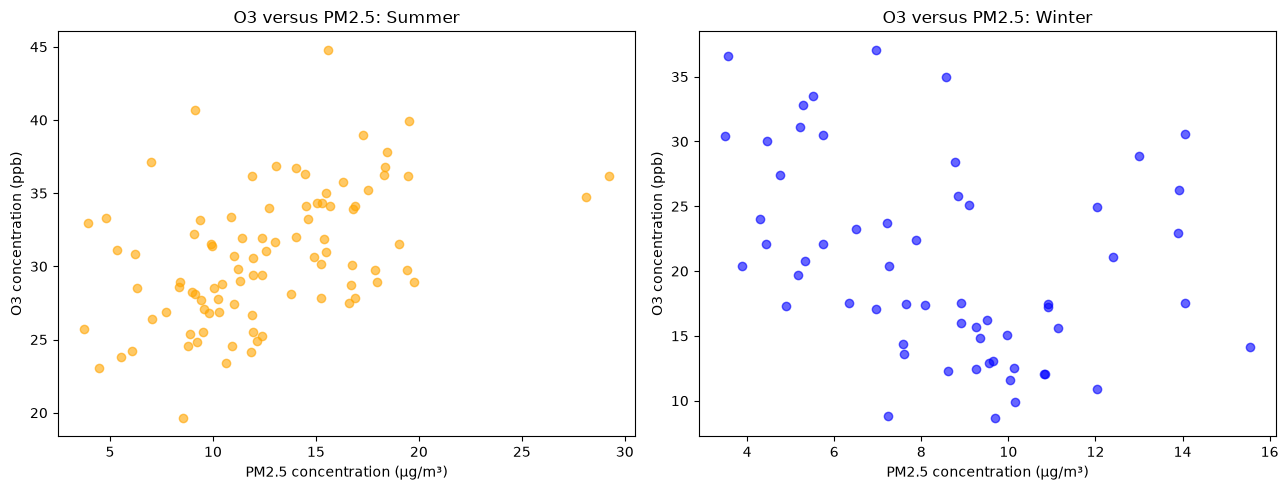

In [8]:
# Create summer and winter plots
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Summer
axes[0].scatter(summer['PM2.5'],summer['O3'],color='orange',alpha=0.6)

axes[0].set_xlabel('PM2.5 concentration (µg/m³)')
axes[0].set_ylabel('O3 concentration (ppb)')
axes[0].set_title('O3 versus PM2.5: Summer')

# Winter
axes[1].scatter(winter['PM2.5'],winter['O3'],color='blue',alpha=0.6)

axes[1].set_xlabel('PM2.5 concentration (µg/m³)')
axes[1].set_ylabel('O3 concentration (ppb)')
axes[1].set_title('O3 versus PM2.5: Winter')

plt.tight_layout()
plt.show()

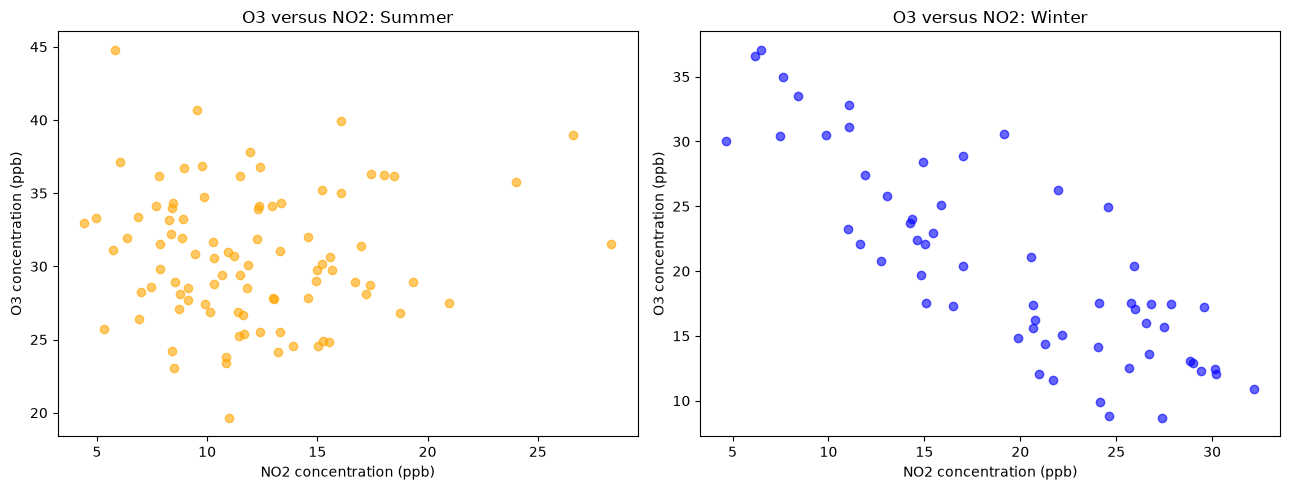

In [9]:
# Create summer and winter plots for O3 and NO2
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Summer
axes[0].scatter(summer['NO2'],summer['O3'],color='orange',alpha=0.6)

axes[0].set_xlabel('NO2 concentration (ppb)')
axes[0].set_ylabel('O3 concentration (ppb)')
axes[0].set_title('O3 versus NO2: Summer')

# Winter
axes[1].scatter(winter['NO2'],winter['O3'],color='blue',alpha=0.6)

axes[1].set_xlabel('NO2 concentration (ppb)')
axes[1].set_ylabel('O3 concentration (ppb)')
axes[1].set_title('O3 versus NO2: Winter')

plt.tight_layout()
plt.show()

In [10]:
# Convert the date column to datetime
df['Date (Local)'] = pd.to_datetime(df['Date (Local)'])

# Create a season column
df['Season'] = df['Date (Local)'].dt.month.map({12: 'Winter',1: 'Winter',2: 'Winter',6: 'Summer',7: 'Summer',8: 'Summer'})

# Keep only summer and winter observations
df = df[df['Season'].isin(['Summer', 'Winter'])]

# Remove missing data
df = df.dropna(subset=['O3', 'NO2', 'PM2.5', 'Season'])

print(df['Season'].value_counts())
plt.show()


Season
Summer    92
Winter    59
Name: count, dtype: int64


In [11]:

x=df[['O3', 'NO2', 'PM2.5']]
y=df['Season']

# Separate the test data
X_train_val, X_test, y_train_val, y_test = train_test_split(x,y,test_size=0.20,random_state=42,stratify=y)

In [12]:
# Separate training and validation data
X_train, X_validation, y_train, y_validation = train_test_split(X_train_val,y_train_val,test_size=0.25,random_state=42,stratify=y_train_val)

In [13]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_validation_scaled = scaler.transform(X_validation)

print("Training data:", X_train.shape)
print("Validation data:", X_validation.shape)
print("Test data:", X_test.shape)

Training data: (90, 3)
Validation data: (30, 3)
Test data: (31, 3)


In [14]:
# Test a range of ridge penalties
alpha_values = np.logspace(-4, 4, 50)
training_errors = []
validation_errors = []

for alpha in alpha_values:
    model = RidgeClassifier(alpha=alpha)
    model.fit(X_train_scaled, y_train)
    training_errors.append(1 - accuracy_score(y_train, model.predict(X_train_scaled)))
    validation_errors.append(1 - accuracy_score(
        y_validation, model.predict(X_validation_scaled)))

best_training_alpha = alpha_values[np.argmin(training_errors)]
best_validation_alpha = alpha_values[np.argmin(validation_errors)]

print('Optimal training alpha:', best_training_alpha)
print('Lowest training error:', min(training_errors))
print('Optimal validation alpha:', best_validation_alpha)
print('Lowest validation error:', min(validation_errors))

Optimal training alpha: 0.0001
Lowest training error: 0.12222222222222223
Optimal validation alpha: 159.98587196060572
Lowest validation error: 0.033333333333333326


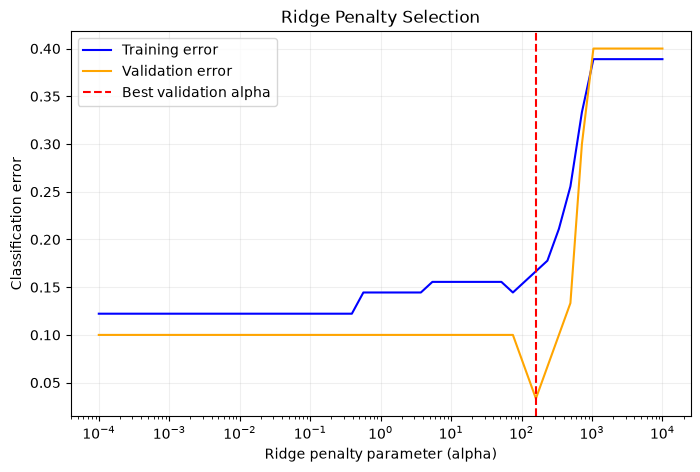

In [15]:
plt.figure(figsize=(8, 5))
plt.semilogx(alpha_values,training_errors,label='Training error',color='blue')
plt.semilogx(alpha_values,validation_errors,label='Validation error',color='orange')
plt.axvline(best_validation_alpha,color='red',linestyle='--',label='Best validation alpha')
plt.xlabel('Ridge penalty parameter (alpha)')
plt.ylabel('Classification error')
plt.title('Ridge Penalty Selection')
plt.legend()
plt.grid(alpha=0.2)
plt.show()

In [16]:
# Combine the training and validation data
final_scaler = StandardScaler()
X_train_val_scaled = final_scaler.fit_transform(X_train_val)
X_test_scaled = final_scaler.transform(X_test)


final_ridge_model = RidgeClassifier(alpha=best_validation_alpha)
final_ridge_model.fit(X_train_scaled,y_train)
ridge_test_prediction = final_ridge_model.predict(X_test_scaled)
ridge_test_accuracy = accuracy_score(y_test,ridge_test_prediction)
ridge_test_error = 1 - ridge_test_accuracy

print("Ridge test accuracy:", ridge_test_accuracy)
print("Ridge final test error:", ridge_test_error)
print("Final ridge test error (%):",ridge_test_error * 100)

Ridge test accuracy: 0.8387096774193549
Ridge final test error: 0.16129032258064513
Final ridge test error (%): 16.129032258064512


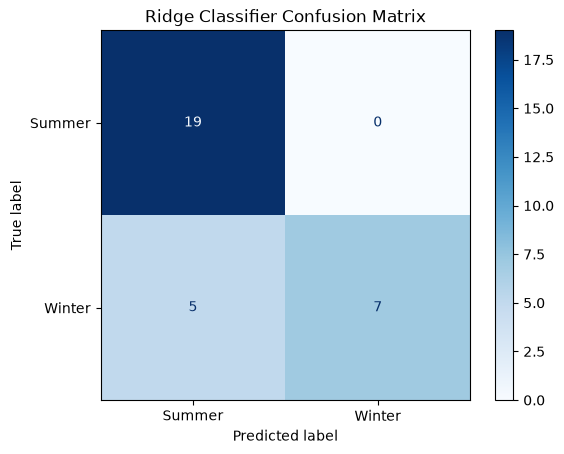

In [17]:
ConfusionMatrixDisplay.from_predictions(y_test,ridge_test_prediction,cmap='Blues')
plt.title('Ridge Classifier Confusion Matrix')
plt.show()

In [18]:
# Repeat only the training/validation split; keep the final test set untouched
for seed in [1, 10, 42, 100]:
    X_tr, X_val, y_tr, y_val = train_test_split(
        X_train_val, y_train_val, test_size=0.25,
        random_state=seed, stratify=y_train_val)

    repeat_scaler = StandardScaler()
    X_tr_scaled = repeat_scaler.fit_transform(X_tr)
    X_val_scaled = repeat_scaler.transform(X_val)

    errors = []
    for alpha in alpha_values:
        model = RidgeClassifier(alpha=alpha)
        model.fit(X_tr_scaled, y_tr)
        errors.append(1 - accuracy_score(y_val, model.predict(X_val_scaled)))

    best_index = np.argmin(errors)
    print('Seed:', seed,
          'Best alpha:', alpha_values[best_index],
          'Validation error:', errors[best_index])

Seed: 1 Best alpha: 24.420530945486497 Validation error: 0.16666666666666663
Seed: 10 Best alpha: 75.43120063354607 Validation error: 0.06666666666666665
Seed: 42 Best alpha: 159.98587196060572 Validation error: 0.033333333333333326
Seed: 100 Best alpha: 0.0001 Validation error: 0.1333333333333333


In [19]:
# Compare with approximately unpenalized logistic regression
logistic_model = LogisticRegression(C=1e6, max_iter=1000)
logistic_model.fit(X_train_val_scaled, y_train_val)
logistic_prediction = logistic_model.predict(X_test_scaled)
logistic_test_error = 1 - accuracy_score(y_test, logistic_prediction)

print('Ridge test error:', ridge_test_error)
print('Logistic regression test error:', logistic_test_error)

Ridge test error: 0.16129032258064513
Logistic regression test error: 0.09677419354838712
